In [51]:
# ============================================================
# 1. Import Libraries
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout,
    Layer, Input
)
from tensorflow.keras.models import Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# ============================================================
# Hyperparameters
# ============================================================

# Text preprocessing
vocab_size = 10000
max_length = 35

# Data split (60:20:20)
test_size = 0.20      # fraction of full data held out for test
val_size = 0.25       # fraction of remaining 80% used for validation
random_state = 42

# Model architecture
embedding_dim = 100
lstm_units = 64
dense_units = 64
dropout_rate_1 = 0.4  # after attention
dropout_rate_2 = 0.3  # after dense layer

# Training
learning_rate = 0.0005  # Keras Adam default
epochs = 20
batch_size = 64
patience = 4           # early stopping

# Output folder for saved model and results (created next to the notebook)
import os
output_dir = "output"
os.makedirs(output_dir, exist_ok=True)

In [53]:
# ============================================================
# 2. Load Dataset
# ============================================================

# Download "Twitter US Airline Sentiment" dataset from Kaggle
# https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
import os
import kagglehub

dataset_path = kagglehub.dataset_download("crowdflower/twitter-airline-sentiment")
print("Dataset downloaded to:", dataset_path)

df = pd.read_csv(os.path.join(dataset_path, "Tweets.csv"))

print(df.head())
print(df.columns)
print("Dataset shape:", df.shape)

# Keep required columns
df = df[['text', 'airline_sentiment']].dropna()

# Remove empty tweets
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'] != '']

print("\nSentiment distribution:")
print(df['airline_sentiment'].value_counts())

Dataset downloaded to: /home/rito/.cache/kagglehub/datasets/crowdflower/twitter-airline-sentiment/versions/4
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  

In [ ]:
# ============================================================
# 3. One-Hot Encode Sentiment Labels
# ============================================================

# Fixed order for consistent class interpretation
class_names = ['negative', 'neutral', 'positive']

df = df[df['airline_sentiment'].isin(class_names)].copy()

labels = pd.get_dummies(
    pd.Categorical(
        df['airline_sentiment'],
        categories=class_names
    )
).astype(int)

y = labels.to_numpy()

print("\nOne-hot encoded labels:")
print(labels.head())
print("Y shape:", y.shape)


One-hot encoded labels:
   negative  neutral  positive
0         0        1         0
1         0        0         1
2         0        1         0
3         1        0         0
4         1        0         0
Y shape: (14640, 3)


In [55]:
# ============================================================
# 4. Text Preprocessing
# ============================================================

X = df['text'].to_numpy()

X_encoded = [
    one_hot(sentence, vocab_size)
    for sentence in X
]

X_padded = pad_sequences(
    X_encoded,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("\nX shape:", X_padded.shape)
print("Y shape:", y.shape)


X shape: (14640, 35)
Y shape: (14640, 3)


In [56]:
# ============================================================
# 5. Train-Validation-Test Split: 60:20:20
# ============================================================

# First split: 80% temporary, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X_padded,
    y,
    test_size=test_size,
    random_state=random_state,
    stratify=np.argmax(y, axis=1)
)

# Second split: 60% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=val_size,
    random_state=random_state,
    stratify=np.argmax(y_temp, axis=1)
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 8784
Validation samples: 2928
Testing samples: 2928


In [57]:
# ============================================================
# 6. Define Attention Layer
# ============================================================

class AttentionLayer(Layer):

    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):

        # Learnable attention weight vector
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )

        super(AttentionLayer, self).build(input_shape)

    def call(self, inputs):

        # inputs shape: (batch_size, max_length, hidden_units)

        # Calculate attention scores for each time step
        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        # Shape: (batch_size, max_length)
        scores = tf.squeeze(scores, axis=-1)

        # Convert scores into attention weights
        attention_weights = tf.nn.softmax(scores, axis=1)

        # Shape: (batch_size, max_length, 1)
        attention_weights = tf.expand_dims(
            attention_weights, axis=-1
        )

        # Weighted sum of LSTM outputs
        context_vector = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        # Shape: (batch_size, hidden_units)
        return context_vector

In [58]:
# ============================================================
# 7. Build LSTM + Attention Model
# ============================================================

inputs = Input(shape=(max_length,), name="tweet_input")

# Convert word IDs into dense vectors
embedding = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    name="embedding"
)(inputs)

# Return output for every time step
lstm_output = LSTM(
    lstm_units,
    return_sequences=True,
    name="lstm"
)(embedding)

# Apply attention
context_vector = AttentionLayer(name="attention")(lstm_output)

# Classification layers
x = Dropout(dropout_rate_1)(context_vector)
x = Dense(dense_units, activation='relu')(x)
x = Dropout(dropout_rate_2)(x)

outputs = Dense(
    3,
    activation='softmax',
    name="sentiment_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="LSTM_Attention_Sentiment"
)

model.summary()

Model: "LSTM_Attention_Sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tweet_input (InputLayer)        │ (None, 35)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 35, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 35, 64)         │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 64)             │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,046,660 (3.99 MB)

 Trainable params: 1,046,660 (3.99 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
# ============================================================
# 8. Compile Model
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [60]:
# ============================================================
# 9. Train Model
# ============================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=patience,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.6414 - loss: 0.8624 - val_accuracy: 0.7018 - val_loss: 0.6943
Epoch 2/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.7322 - loss: 0.6169 - val_accuracy: 0.7363 - val_loss: 0.6075
Epoch 3/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.7865 - loss: 0.5047 - val_accuracy: 0.7343 - val_loss: 0.6375
Epoch 4/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8423 - loss: 0.4307 - val_accuracy: 0.7715 - val_loss: 0.5869
Epoch 5/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.8823 - loss: 0.3487 - val_accuracy: 0.7783 - val_loss: 0.6465
Epoch 6/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9053 - loss: 0.2887 - val_accuracy: 0.7626 - val_loss: 0.6545
Epoch 7/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9242 - loss: 0.2428 - val_accuracy: 0.7654 - val_loss: 0.7267
Epoch 8/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9374 - loss: 0.2030 - val_ac

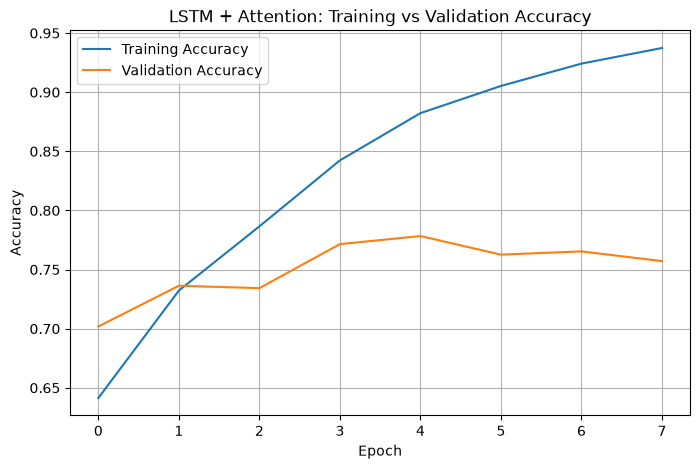

In [61]:
# ============================================================
# 10. Plot Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('LSTM + Attention: Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

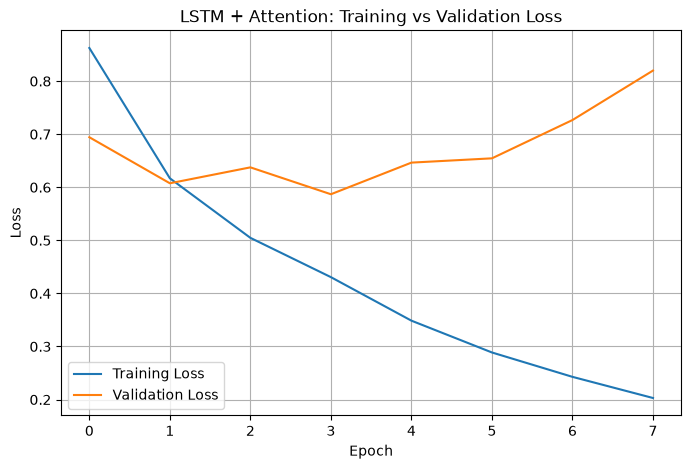

In [62]:
# ============================================================
# 11. Plot Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LSTM + Attention: Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [63]:
# ============================================================
# 12. Evaluate Model
# ============================================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Test Loss: 0.5871464610099792
Test Accuracy: 0.7783470153808594


In [64]:
# ============================================================
# 13. Predictions
# ============================================================

y_pred_prob = model.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("\nPredicted:", y_pred[:10])
print("Actual   :", y_true[:10])

print(
    "\nAccuracy Score:",
    accuracy_score(y_true, y_pred)
)


Predicted: [1 1 0 0 0 0 0 0 0 1]
Actual   : [1 2 0 0 0 0 1 0 0 0]

Accuracy Score: 0.7783469945355191


In [65]:
# ============================================================
# 14. Classification Report
# ============================================================

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negative       0.85      0.88      0.87      1835
     neutral       0.58      0.64      0.61       620
    positive       0.77      0.57      0.66       473

    accuracy                           0.78      2928
   macro avg       0.73      0.70      0.71      2928
weighted avg       0.78      0.78      0.78      2928



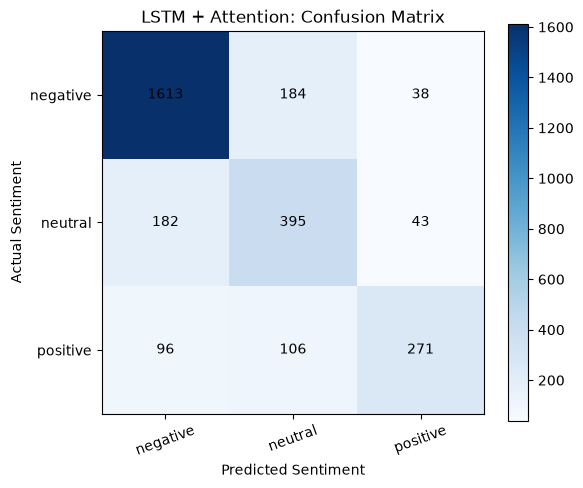

In [66]:
# ============================================================
# 15. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')

plt.title('LSTM + Attention: Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.xticks(range(3), class_names, rotation=20)
plt.yticks(range(3), class_names)

plt.colorbar()

for i in range(3):
    for j in range(3):
        plt.text(
            j, i, str(cm[i, j]),
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# 16. Predict New Tweet
# ============================================================

tweet = "The flight was amazing and the staff were very helpful"

tweet_encoded = one_hot(tweet, vocab_size)

tweet_padded = pad_sequences(
    [tweet_encoded],
    maxlen=max_length,
    padding='post',
    truncating='post'
)

prediction = model.predict(tweet_padded, verbose=0)

predicted_class = np.argmax(prediction[0])

print("\nNew Tweet:", tweet)
print("Prediction probabilities:")

for i, sentiment in enumerate(class_names):
    print(f"{sentiment}: {prediction[0][i]:.4f}")

print("Predicted Sentiment:", class_names[predicted_class])


New Tweet: The flight was amazing and the staff were very helpful
Prediction probabilities:
negative: 0.0083
neutral: 0.0471
positive: 0.9446
Predicted Sentiment: positive


In [68]:
# ============================================================
# 17. Save Trained Model (only if validation accuracy improved)
# ============================================================

import os
import json
from datetime import datetime

model_path = os.path.join(output_dir, "LSTM_Attention_Sentiment.keras")
best_score_path = os.path.join(output_dir, "LSTM_Attention_Sentiment_best.json")

# Validation accuracy of the current model
_, current_val_accuracy = model.evaluate(X_val, y_val, verbose=0)

# Validation accuracy of the previously saved model (if any)
previous_val_accuracy = None
if os.path.exists(model_path) and os.path.exists(best_score_path):
    with open(best_score_path) as f:
        previous_val_accuracy = json.load(f)["val_accuracy"]

print("Current validation accuracy :", current_val_accuracy)
print("Previous best val accuracy  :", previous_val_accuracy)

if previous_val_accuracy is None or current_val_accuracy > previous_val_accuracy:
    # Save complete model architecture, weights and optimizer state
    model.save(model_path)

    with open(best_score_path, "w") as f:
        json.dump({
            "val_accuracy": float(current_val_accuracy),
            "saved_at": datetime.now().isoformat(timespec="seconds"),
            "hyperparameters": {
                "vocab_size": vocab_size,
                "max_length": max_length,
                "embedding_dim": embedding_dim,
                "lstm_units": lstm_units,
                "dense_units": dense_units,
                "dropout_rate_1": dropout_rate_1,
                "dropout_rate_2": dropout_rate_2,
                "learning_rate": learning_rate,
                "epochs": epochs,
                "batch_size": batch_size,
                "patience": patience
            }
        }, f, indent=4)

    print("Validation accuracy improved - model saved successfully!")
else:
    print("Validation accuracy did not improve - keeping the previously saved model.")

Current validation accuracy : 0.7715163826942444
Previous best val accuracy  : 0.744193971157074
Validation accuracy improved - model saved successfully!


In [69]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "AttentionLayer": AttentionLayer
    }
)

print("Model loaded successfully!")

Model loaded successfully!


In [70]:
# ============================================================
# 19. Evaluate Saved Model on Test Data
# ============================================================

test_loss, test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== SAVED MODEL RESULTS ==========")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7783 - loss: 0.5871

========== SAVED MODEL RESULTS ==========
Test Loss: 0.5871464610099792
Test Accuracy: 0.7783470153808594


In [71]:
test_loss, test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7783 - loss: 0.5871

Test Loss: 0.5871464610099792
Test Accuracy: 0.7783470153808594


In [72]:
y_pred_prob = loaded_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("Predicted:", y_pred[:10])
print("Actual   :", y_true[:10])

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Predicted: [1 1 0 0 0 0 0 0 0 1]
Actual   : [1 2 0 0 0 0 1 0 0 0]


In [73]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

Accuracy: 0.7783469945355191
              precision    recall  f1-score   support

    negative       0.85      0.88      0.87      1835
     neutral       0.58      0.64      0.61       620
    positive       0.77      0.57      0.66       473

    accuracy                           0.78      2928
   macro avg       0.73      0.70      0.71      2928
weighted avg       0.78      0.78      0.78      2928

